# Explore here

El objetivo de este proyecto es hacer un sistema de predicción de ventas

## Importar datos y análisis superficial

In [1]:
import pandas as pd 

ruta = 'https://breathecode.herokuapp.com/asset/internal-link?id=2546&path=sales.csv'

df = pd.read_csv(ruta)

df.head(5)

,date,sales
0,2022-09-03 17:10:08.079328,55.292157
1,2022-09-04 17:10:08.079328,53.803211
2,2022-09-05 17:10:08.079328,58.141693
3,2022-09-06 17:10:08.079328,64.530899
4,2022-09-07 17:10:08.079328,66.013633


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    366 non-null    str    
 1   sales   366 non-null    float64
dtypes: float64(1), str(1)
memory usage: 5.8 KB


- 366 registros

- no hay nulos

- la columna date está en string y debe ser convertida a date time 

In [3]:
# paso date a time series

#conversion
df["date"] = pd.to_datetime(df["date"])

# la seteo como indice del df
df = df.set_index("date")

# almaceno en variable ts y verifico
ts = df.sales
ts.head(3)


date
2022-09-03 17:10:08.079328    55.292157
2022-09-04 17:10:08.079328    53.803211
2022-09-05 17:10:08.079328    58.141693
Name: sales, dtype: float64

In [4]:
df.info() # date deja de aparecer porque ahora es el indice del dataframe

<class 'pandas.DataFrame'>
DatetimeIndex: 366 entries, 2022-09-03 17:10:08.079328 to 2023-09-03 17:10:08.079328
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   sales   366 non-null    float64
dtypes: float64(1)
memory usage: 5.7 KB


In [5]:
df.head(5)

,sales
date,
2022-09-03 17:10:08.079328,55.292157
2022-09-04 17:10:08.079328,53.803211
2022-09-05 17:10:08.079328,58.141693
2022-09-06 17:10:08.079328,64.530899
2022-09-07 17:10:08.079328,66.013633


In [6]:
df.sales.head(5)

date
2022-09-03 17:10:08.079328    55.292157
2022-09-04 17:10:08.079328    53.803211
2022-09-05 17:10:08.079328    58.141693
2022-09-06 17:10:08.079328    64.530899
2022-09-07 17:10:08.079328    66.013633
Name: sales, dtype: float64

In [7]:
#df.date.head(5)
df.index

DatetimeIndex(['2022-09-03 17:10:08.079328', '2022-09-04 17:10:08.079328',
               '2022-09-05 17:10:08.079328', '2022-09-06 17:10:08.079328',
               '2022-09-07 17:10:08.079328', '2022-09-08 17:10:08.079328',
               '2022-09-09 17:10:08.079328', '2022-09-10 17:10:08.079328',
               '2022-09-11 17:10:08.079328', '2022-09-12 17:10:08.079328',
               ...
               '2023-08-25 17:10:08.079328', '2023-08-26 17:10:08.079328',
               '2023-08-27 17:10:08.079328', '2023-08-28 17:10:08.079328',
               '2023-08-29 17:10:08.079328', '2023-08-30 17:10:08.079328',
               '2023-08-31 17:10:08.079328', '2023-09-01 17:10:08.079328',
               '2023-09-02 17:10:08.079328', '2023-09-03 17:10:08.079328'],
              dtype='datetime64[us]', name='date', length=366, freq=None)

In [8]:
print(type(df.index))
print(type(ts))

<class 'pandas.DatetimeIndex'>
<class 'pandas.Series'>


La conversión se ha hecho correctamente, así que seguimos con el proyecto

## Estudiando la time series creada

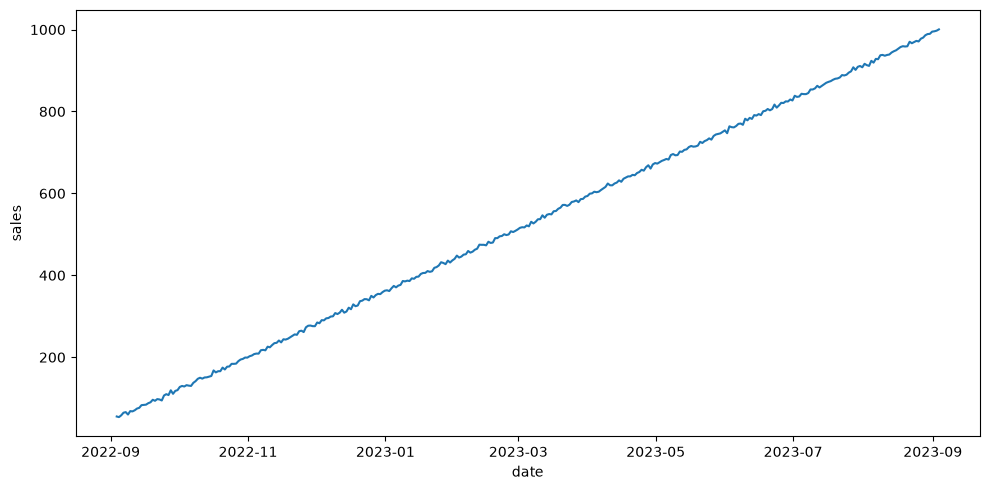

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axis = plt.subplots(figsize=(10, 5))
sns.lineplot(data = ts)
plt.tight_layout()
plt.show()

In [10]:
# vamos a ver el tensor 
import numpy as np

tensor = ts.values           
#tensor.head(3) esto no funciona, tensor no es una serie
# type(tensor) miro el tipo de tensor, que es un array de numpy
print(tensor[:3]) #imprimo 3 primeros elementos del tensor 

[55.29215704 53.80321135 58.1416934 ]


In [11]:
#tengo que importar el modulo statsmodels o la siguiente celda no funciona
!pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


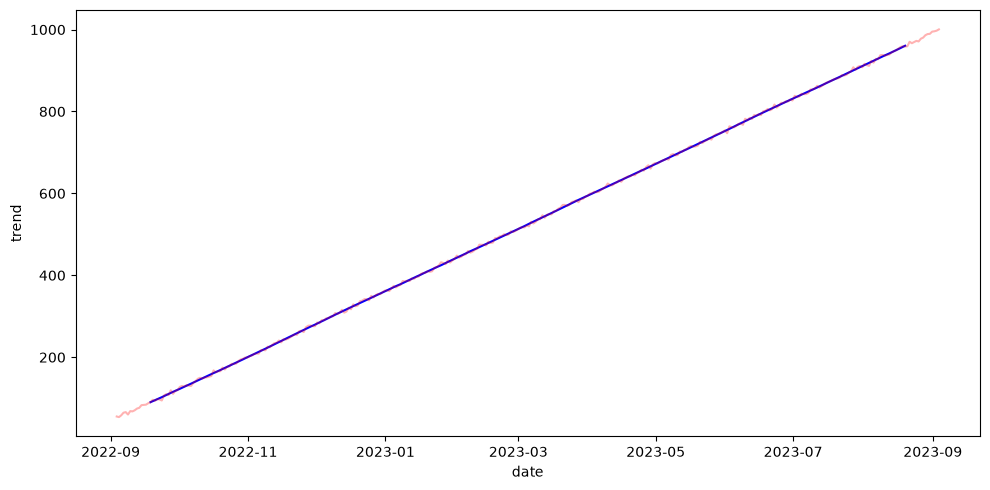

In [12]:
# ahora miramos la tendencia de la serie, para eso vamos a usar un filtro de media movil, que nos permite suavizar la serie y ver la tendencia.
from statsmodels.tsa.seasonal import seasonal_decompose

#variables
decomposition = seasonal_decompose(ts, period=30)  # periodo mensual 
trend = decomposition.trend

#visualizamos
fig, axis = plt.subplots(figsize=(10, 5))
sns.lineplot(data = trend, color = 'blue') # grafico de la tendencia en azul solido
sns.lineplot(data = ts, alpha = 0.3, color = 'red') # grafico de la serie original en rojo transparente
plt.tight_layout()
plt.show()

Tendencia ascendente y lineal de principio a fin de las fechas en las que se recopiló la información (sept. 2022 - sept. 2023)

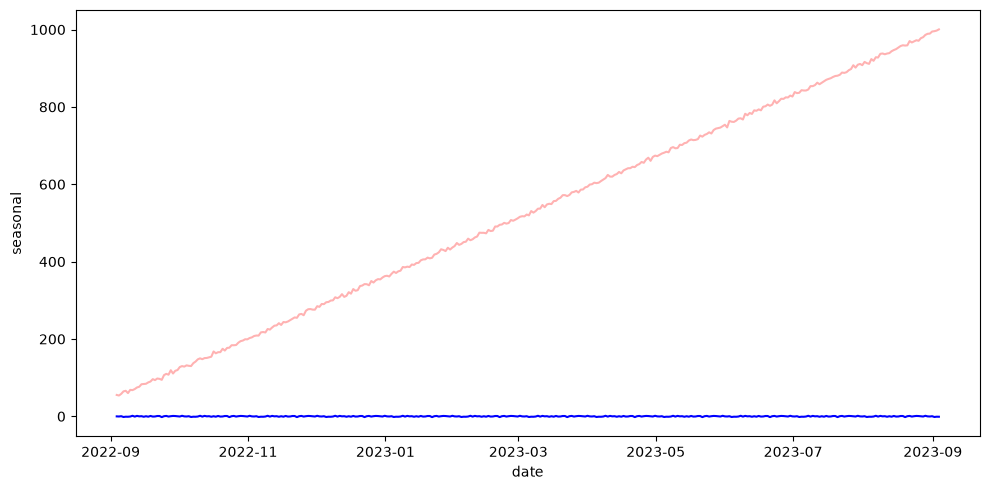

In [13]:
# ahora vamos a ver la estacionariedad

#variables
seasonal = decomposition.seasonal

#visualizamos
fig, axis = plt.subplots(figsize=(10, 5))
sns.lineplot(data = seasonal, color = 'blue') # grafico de la estacionariedad en azul solido 
sns.lineplot(data = ts, alpha = 0.3, color = 'red') # grafico de la serie original en rojo transparente
plt.tight_layout()
plt.show()


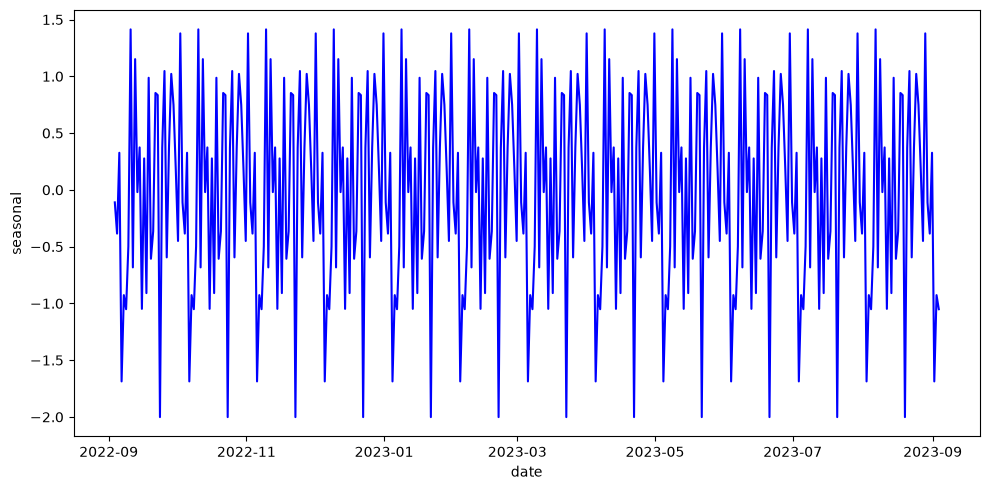

In [14]:
# miramos estacionariedad sola 

fig, axis = plt.subplots(figsize=(10, 5))
sns.lineplot(data = seasonal, color = 'blue') # grafico de la estacionariedad en azul solido 

plt.tight_layout()
plt.show()

En base a lo visto en losgráficos no hay estacionariedad, puesto que cuando la graficamos individualmente podemos ver cómo va todo el rato de -2 a 2 en el eje vertical. De todos modos, podemos aplicar el test de Dickey Fuller para verificar.

In [15]:
from statsmodels.tsa.stattools import adfuller

def test_stationarity(timeseries):
    print("Dickey-Fuller test results:")
    dftest = adfuller(timeseries, autolag = "AIC")
    dfoutput = pd.Series(dftest[0:4], index = ["Test Statistic", "p-value", "#Lags Used", "Number of Observations Used"])
    for key,value in dftest[4].items():
        dfoutput["Critical Value (%s)"%key] = value
    return dfoutput

test_stationarity(ts)

Dickey-Fuller test results:


/tmp/ipykernel_58016/4067147279.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(timeseries, autolag = "AIC")


Test Statistic                   0.545414
p-value                          0.986190
#Lags Used                      13.000000
Number of Observations Used    352.000000
Critical Value (1%)             -3.449065
Critical Value (5%)             -2.869786
Critical Value (10%)            -2.571163
dtype: float64

El test plantea como hipótesis nula que la serie no es estacionaria, frente a la hipótesis alternativa de que sí lo es. El p-value obtenido (0.986) es muy superior al nivel de significancia habitual (0.05), por lo que no existe evidencia suficiente para rechazar nuestra hipótesis nula. Por tanto, se concluye que la serie de ventas no es estacionaria.

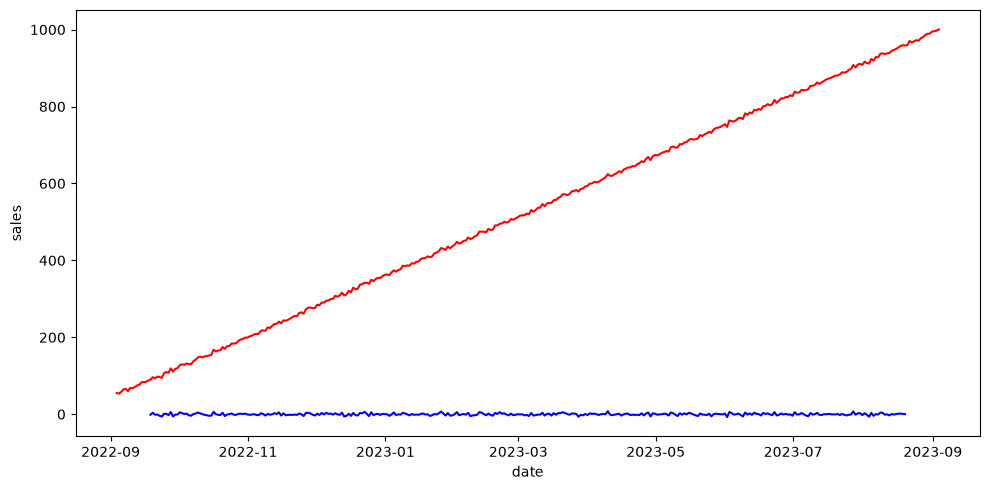

In [16]:
# vamos a ver el ruido de la serie 
ruido = decomposition.resid

fig, axis = plt.subplots(figsize=(10, 5))
sns.lineplot(data = ts, color = 'red')
sns.lineplot(data = ruido, color = 'blue')
plt.tight_layout()
plt.show()

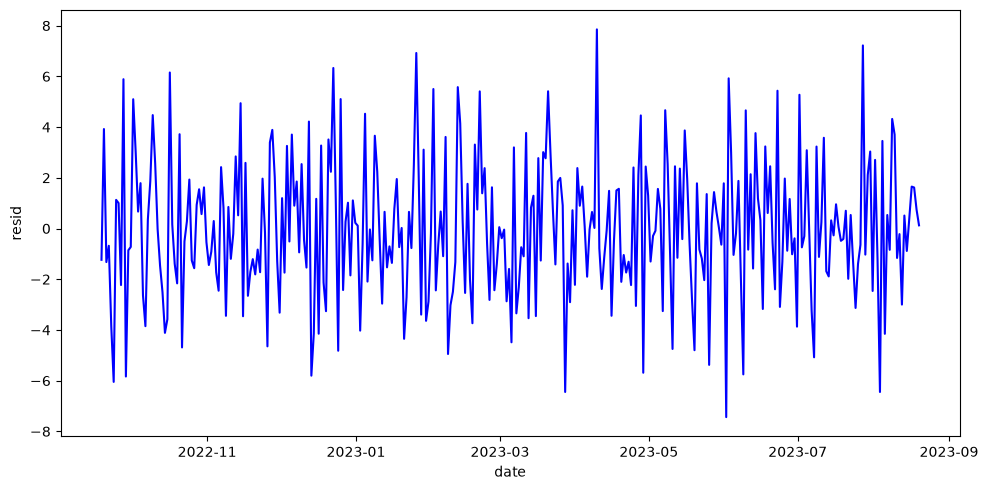

In [17]:
# vamos a ver el ruido de la serie solo
ruido = decomposition.resid

fig, axis = plt.subplots(figsize=(10, 5))

sns.lineplot(data = ruido, color = 'blue')
plt.tight_layout()
plt.show()

No hay apenas ruido en la serie.

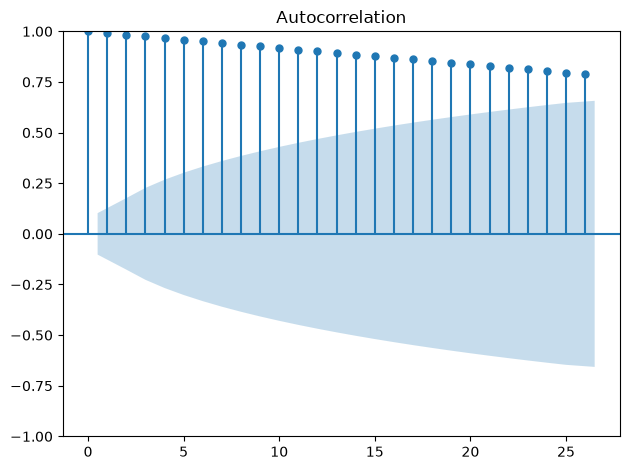

In [18]:
# terminamos viendo la correlación
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(df)

plt.tight_layout()

plt.show()

Correlación muy elevada en el primer retardo (cercana a 1) que decrece de forma muy lenta y lineal, manteniéndose en torno a 0.8. Todos los retardos se sitúan fuera de la banda de confianza (zona sombreada), por lo que son estadísticamente significativos. Esto confirma la no estacionariedad detectada con el test de Dickey-Fuller.

## Entrenar un ARIMA

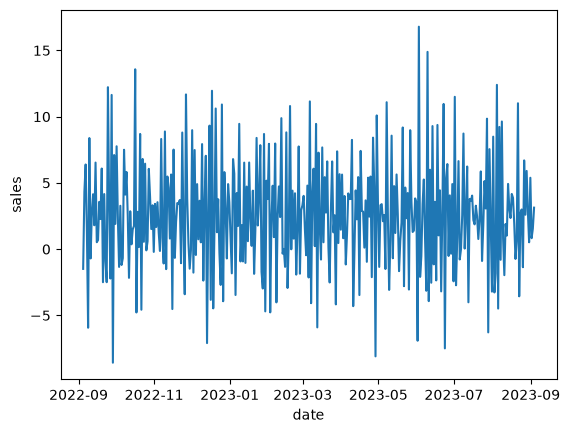

Dickey-Fuller test results:


/tmp/ipykernel_58016/4067147279.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(timeseries, autolag = "AIC")


Test Statistic                -9.430263e+00
p-value                        5.212954e-16
#Lags Used                     1.200000e+01
Number of Observations Used    3.520000e+02
Critical Value (1%)           -3.449065e+00
Critical Value (5%)           -2.869786e+00
Critical Value (10%)          -2.571163e+00
dtype: float64

In [19]:
# hay que volver la serie estacionaria 
serie_stationary = ts.diff().dropna()
sns.lineplot(data = serie_stationary)
plt.show()

test_stationarity(serie_stationary)

In [20]:
!pip install pmdarima # tengo que instalar el modulo primero

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [21]:
# tamaño del test
test_size = 30 

# conjuntos de datos
train = ts.iloc[:-test_size]
test = ts.iloc[-test_size:]

print(train.shape, test.shape)

(336,) (30,)


In [22]:
# llamamos a diff, que genera un nulo en la primera fila, asi que nos cargamos ese nulo que se generará
train_stationary = train.diff().dropna()

# test de estacionariedad
test_stationarity(train_stationary)

Dickey-Fuller test results:


/tmp/ipykernel_58016/4067147279.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  dftest = adfuller(timeseries, autolag = "AIC")


Test Statistic                -8.670863e+00
p-value                        4.550432e-14
#Lags Used                     1.200000e+01
Number of Observations Used    3.220000e+02
Critical Value (1%)           -3.450823e+00
Critical Value (5%)           -2.870558e+00
Critical Value (10%)          -2.571575e+00
dtype: float64

In [23]:
# creamos el modelo
from pmdarima import auto_arima
model = auto_arima(train_stationary, seasonal=False, trace=True)
model.summary()

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(0,0,0)[0]             : AIC=inf, Time=0.67 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=2035.035, Time=0.01 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=2031.225, Time=0.03 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=2033.442, Time=0.03 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=2007.916, Time=0.03 sec
 ARIMA(3,0,0)(0,0,0)[0]             : AIC=1949.550, Time=0.03 sec
 ARIMA(4,0,0)(0,0,0)[0]             : AIC=1915.848, Time=0.04 sec
 ARIMA(5,0,0)(0,0,0)[0]             : AIC=1883.374, Time=0.07 sec
 ARIMA(5,0,1)(0,0,0)[0]             : AIC=inf, Time=0.86 sec
 ARIMA(4,0,1)(0,0,0)[0]             : AIC=inf, Time=0.40 sec
 ARIMA(5,0,0)(0,0,0)[0] intercept   : AIC=1741.262, Time=0.44 sec
 ARIMA(4,0,0)(0,0,0)[0] intercept   : AIC=1746.180, Time=0.52 sec
 ARIMA(5,0,1)(0,0,0)[0] intercept   : AIC=1700.564, Time=0.49 sec
 ARIMA(4,0,1)(0,0,0)[0] intercept   : AIC=1699.401, Time=0.64 sec
 ARIMA(3,0,1)(0,0,0)[0] intercept   : AIC=1699.1

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                  335
Model:               SARIMAX(0, 0, 2)   Log Likelihood                -843.686
Date:                Wed, 21 Oct 2026   AIC                           1695.371
Time:                        15:37:35   BIC                           1710.628
Sample:                    09-04-2022   HQIC                          1701.454
                         - 08-04-2023                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      2.5955      0.011    241.857      0.000       2.575       2.617
ma.L1         -1.0345      0.051    -20.159      0.000      -1.135      -0.934
ma.L2          0.0966      0.051      1.891      0.059      -0.004       0.197
sigma2         8.9567      0.731     12.256      0.000       7.524      10.389
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 0.64
Prob(Q):                              0.98   Prob(JB):                         0.73
Heteroskedasticity (H):               0.88   Skew:                             0.07
Prob(H) (two-sided):                  0.49   Kurtosis:                         2.84
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

## Predicción

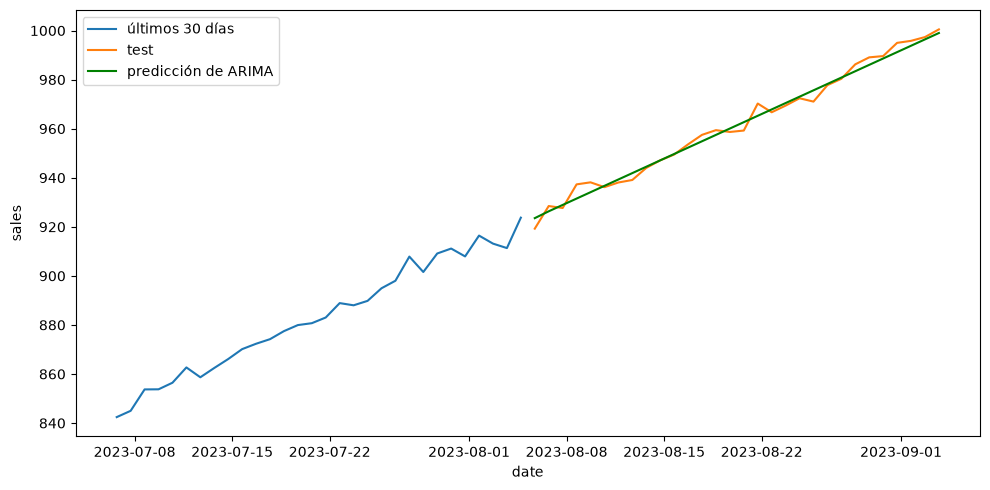

In [24]:
forecast_diff = model.predict(len(test))

# reconstruir a escala original: acumular la diferencia sobre el último valor del train
last_level = train.iloc[-1]
forecast = forecast_diff.cumsum() + last_level
forecast.index = test.index  # alinear fechas para poder comparar

#visualizamos los datos y la prediccion
fig, axis = plt.subplots(figsize=(10, 5))

sns.lineplot(data=train.iloc[-30:], label="últimos 30 días") #datos de los ultimos 30 dias 
sns.lineplot(data=test, label="test")  #datos de test
sns.lineplot(data=forecast, label="predicción de ARIMA", color="green")  #la prediccion del ARIMA
plt.tight_layout()
plt.show()

In [25]:
# vamos a medir el rendimiento
from sklearn.metrics import mean_squared_error, mean_absolute_error


mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))
mape = np.mean(np.abs((test - forecast) / test)) * 100

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

MAE: 2.07
RMSE: 2.58
MAPE: 0.22%


## Guardar el modelo 

In [27]:
import joblib
import os

dir = '/workspaces/alternative-time-series-Pablo-Martin/models'

model_path = os.path.join(dir, "ARIMA.pkl")
joblib.dump(model, model_path)

print(f"Modelo guardado en: {model_path}")

Modelo guardado en: /workspaces/alternative-time-series-Pablo-Martin/models/ARIMA.pkl
